# E1. 가상 팹 sanity 확인

주입한 결함(S1: ETCH-03/B, 12~18일차, Edge-Ring)과 함정(공통 병목 설비 CLN-01)이 데이터에 의도대로 나타나는지 확인한다.

- 이 노트북은 **시뮬레이션 자체를 검사**하므로 정답 컬럼 `true_pattern`을 쓴다. 03의 원인 분석에서는 쓰지 않는다.
- 데이터는 `uv run python -m fabtrace.sim.generate --seed 42`로 만든다.
- 기록: `results/experiments/` 의 E1 파일

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


def find_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    raise FileNotFoundError("pyproject.toml이 있는 레포 루트를 찾지 못함")


ROOT = find_root()
PROCESSED = ROOT / "data" / "processed"
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

genealogy = pd.read_parquet(PROCESSED / "genealogy.parquet")
wafers = pd.read_parquet(PROCESSED / "wafers.parquet")
gt = json.loads((PROCESSED / "ground_truth.json").read_text(encoding="utf-8"))

PATTERN, CAUSE = gt["pattern"], gt["chamber"]
START, END = gt["window"]["start_day"], gt["window"]["end_day"]
BOTTLENECK = "CLN-01/A"
print(f"{gt['scenario']} seed {gt['seed']}: {CAUSE}, {START}~{END}일차, {PATTERN}")
print(f"웨이퍼 {len(wafers):,}장, 영향 {gt['n_affected_wafers']}장, 주입 {gt['n_injected_wafers']}장")

S1 seed 42: ETCH-03/B, 12~18일차, Edge-Ring
웨이퍼 8,000장, 영향 159장, 주입 61장


## 확인 1. 주입 기간에 원인 챔버만 튀는가

ETCH 단계를 지난 날짜 기준으로, 챔버별 하루 Edge-Ring 비율을 본다.

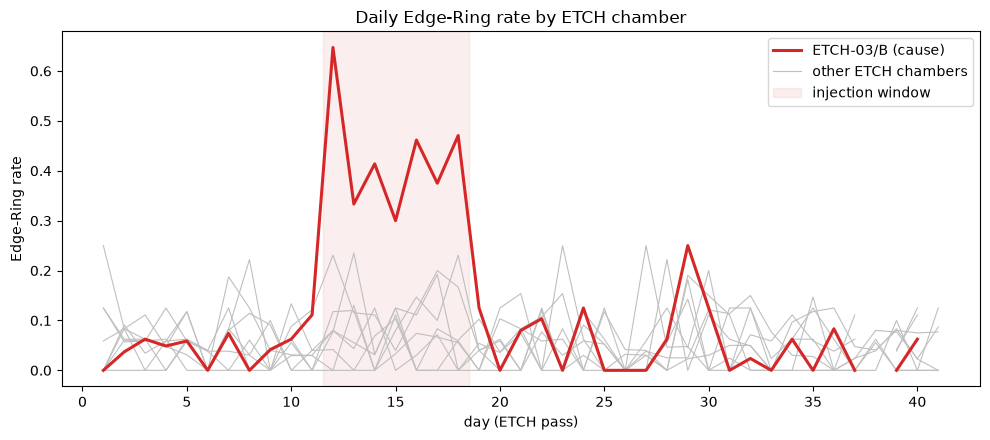

In [2]:
base = pd.Timestamp(gt["window"]["start_ts"]) - pd.Timedelta(days=START - 1)
etch = genealogy[genealogy["step"] == gt["step"]].merge(wafers[["wafer_id", "true_pattern"]], on="wafer_id")
etch["etch_day"] = (etch["ts"].dt.normalize() - base).dt.days + 1
etch["is_pattern"] = etch["true_pattern"] == PATTERN

daily = etch.groupby(["chamber", "etch_day"])["is_pattern"].mean().unstack(0)

fig, ax = plt.subplots(figsize=(10, 4.5))
for chamber in daily.columns:
    if chamber == CAUSE:
        continue
    ax.plot(daily.index, daily[chamber], color="0.75", lw=0.8)
ax.plot(daily.index, daily[CAUSE], color="tab:red", lw=2.2, label=f"{CAUSE} (cause)")
ax.plot([], [], color="0.75", lw=0.8, label="other ETCH chambers")
ax.axvspan(START - 0.5, END + 0.5, color="tab:red", alpha=0.08, label="injection window")
ax.set_xlabel("day (ETCH pass)")
ax.set_ylabel(f"{PATTERN} rate")
ax.set_title(f"Daily {PATTERN} rate by ETCH chamber")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIGURES / "e1_etch_daily_rate.png", dpi=150)
plt.show()

In [3]:
in_window = etch["etch_day"].between(START, END)
summary = pd.DataFrame({
    "구간": [f"{CAUSE}, 주입 기간", f"{CAUSE}, 그 외", "다른 ETCH 챔버, 주입 기간", "다른 ETCH 챔버, 그 외"],
    "mask": [
        (etch["chamber"] == CAUSE) & in_window,
        (etch["chamber"] == CAUSE) & ~in_window,
        (etch["chamber"] != CAUSE) & in_window,
        (etch["chamber"] != CAUSE) & ~in_window,
    ],
})
summary["웨이퍼"] = summary["mask"].map(lambda m: int(m.sum()))
summary[f"{PATTERN} 비율"] = summary["mask"].map(lambda m: f"{etch.loc[m, 'is_pattern'].mean():.1%}")
summary.drop(columns="mask")

,구간,웨이퍼,Edge-Ring 비율
0,"ETCH-03/B, 주입 기간",159,41.5%
1,"ETCH-03/B, 그 외",590,4.7%
2,"다른 ETCH 챔버, 주입 기간",1242,7.1%
3,"다른 ETCH 챔버, 그 외",6009,5.1%


## 확인 2. 단순 집계는 무엇을 원인으로 지목하는가

Edge-Ring 웨이퍼가 거친 횟수를 챔버별로 센다. 03의 베이스라인(방법 A)과 같은 계산이다.

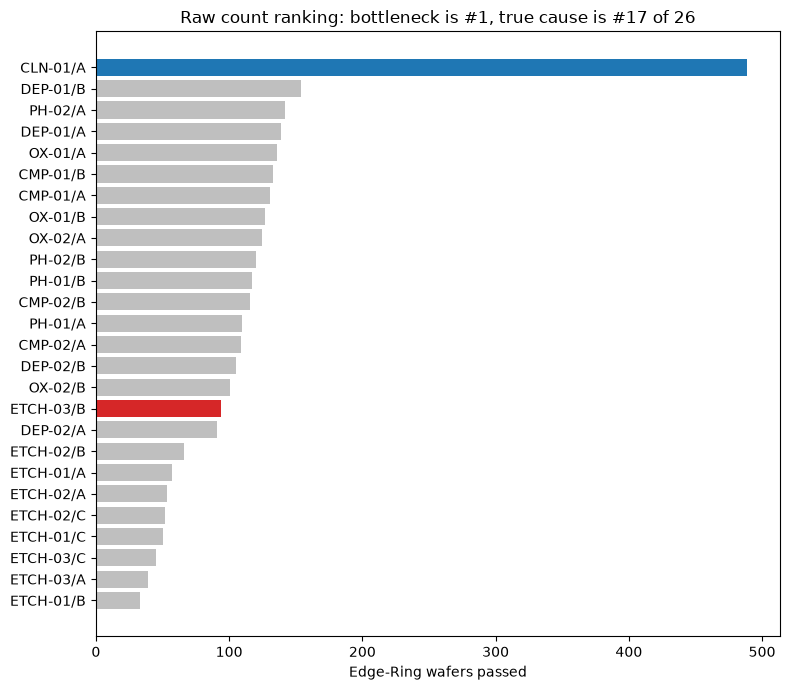

1위: CLN-01/A (489장)
원인 ETCH-03/B: 17위 / 26개 챔버


In [4]:
pattern_wafers = set(wafers.loc[wafers["true_pattern"] == PATTERN, "wafer_id"])
counts = (
    genealogy[genealogy["wafer_id"].isin(pattern_wafers)]["chamber"]
    .value_counts()
    .rename_axis("chamber")
    .reset_index(name="pattern_wafers")
)
counts["rank"] = range(1, len(counts) + 1)
cause_rank = int(counts.loc[counts["chamber"] == CAUSE, "rank"].iloc[0])

colors = ["tab:red" if c == CAUSE else "tab:blue" if c == BOTTLENECK else "0.75" for c in counts["chamber"]]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(counts["chamber"], counts["pattern_wafers"], color=colors)
ax.invert_yaxis()
ax.set_xlabel(f"{PATTERN} wafers passed")
ax.set_title(f"Raw count ranking: bottleneck is #1, true cause is #{cause_rank} of {len(counts)}")
fig.tight_layout()
fig.savefig(FIGURES / "e1_raw_count_rank.png", dpi=150)
plt.show()

print(f"1위: {counts.iloc[0]['chamber']} ({counts.iloc[0]['pattern_wafers']}장)")
print(f"원인 {CAUSE}: {cause_rank}위 / {len(counts)}개 챔버")

In [5]:
# 챔버 하나가 처리하는 웨이퍼 비율: 단순 집계가 무엇을 재는지 보여준다
share = genealogy.groupby(["step", "chamber"])["wafer_id"].nunique() / wafers["wafer_id"].nunique()
share.groupby("step").mean().map("{:.1%}".format).rename("챔버당 평균 처리 비율")

step
CLEAN         100.0%
CMP            25.0%
DEPOSITION     25.0%
ETCH           11.1%
OXIDATION      25.0%
PHOTO          25.0%
Name: 챔버당 평균 처리 비율, dtype: str

## 결론

- 확인 1: ETCH-03/B의 Edge-Ring 비율이 주입 기간에만 41.5%로 올랐다가 평상시 수준(4.7%)으로 돌아왔다. 결함이 의도대로 주입됐다.
- 확인 2: 단순 집계 1위는 병목 CLN-01/A이고, 원인 ETCH-03/B는 26개 중 17위다. 단순 집계는 원인이 아니라 처리량을 잰다.

자세한 해석과 다음 조치: `results/experiments/20261108-E1.md`